TODO: update links becaues I moved files around 

<h1 align="center">Dynamic Routing Data Access Tutorial</h1>
<h3 align="center">Allen Institute / Neural Dynamics</h3>
<h4 align="center">Code Ocean access version</h4>

**Goal:** This tutorial will cover data access, details of the experiment, exploration and scientific analysis.

  We will:
  1. Find & load data packaged as NWB files
  2. Explain the design of the Dynamic Routing task
  3. Visualize task performance
  4. Summarize the brain areas recorded
  5. Explore data around stimulus onset: neural activity, running speed, face motion

For general information about the Dynamic Routing project, see [README.md](../README.md).

For a description of how the NWB files are organized an what each field contains, see the [NWB gile guide](code/NWB_FILE_GUIDE.md) and the [data dictionary](code/742903_2024-10-23_data_dictionary.md)

In [1]:
import pathlib
import warnings
import numcodecs.pickles
numcodecs.pickles.ALLOW_UNSAFE_PICKLE_DECODE = True

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pynwb
import brainglobe_atlasapi as bg

warnings.filterwarnings("ignore", module="hdmf_zarr")  # known issues, can be ignored


In [2]:
# Plot settings 

plt.rcParams.update({
    "figure.figsize": (8, 4),
    "figure.dpi": 110,
    "figure.constrained_layout.use": True,
    "font.size": 15,
    "axes.titlesize": 17,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2,
})

CONTEXT_COLORS = {"vis": "#1f77b4", "aud": "#ff7f0e"}   # rewarded modality (and stimulus modality)
STIM_ORDER = ["vis1", "vis2", "sound1", "sound2", "catch"]
STIM_LABELS = {                                           # vis1 and sound1 are the target stimuli
    "vis1": "vis target", "vis2": "vis non-target",
    "sound1": "aud target", "sound2": "aud non-target",
    "catch": "catch",
}


def shade_blocks(ax, trials, start_col="trial_index", stop_col="trial_index", pad=0.5):
    """Shade the background of each block by its rewarded modality."""
    blocks = trials.groupby("block_index").agg(
        start=(start_col, "min"), stop=(stop_col, "max"), modality=("rewarded_modality", "first"))
    for block in blocks.itertuples():
        ax.axvspan(block.start - pad, block.stop + pad, color=CONTEXT_COLORS[block.modality], alpha=0.12, lw=0)


def add_legend(ax, context=True, **kwargs):
    """Legend with the plotted lines plus (optionally) the block-shading colors, placed outside the axes."""
    handles, _ = ax.get_legend_handles_labels()
    if context:
        handles += [Patch(color=c, alpha=0.25, label=f"{m} rewarded") for m, c in CONTEXT_COLORS.items()]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), **kwargs)

---
## 1. Find & open a NWB file 

Every session in the dataset is listed in the metadata table (`dynamic_routing_metadata.csv`). Each row is one recording session and contains information about the subject, recording session, and behavior performance. 

You can use the table to browse for a session or sessions of interest, then use the `subject_id` and `session_date` as search filters to find the corresponding data. 

<details> 

<summary>Metadata Details</summary>

The complete metadata for each session is also attached to its data asset as `.json` files following the [AIND metadata schema](https://github.com/AllenNeuralDynamics/aind-data-schema). If you need more information about a session, look in the `.json` files attached to each data asset, which hold the complete metadata or adapt the code that generated the metadata table (/code/dynamic_routing_metadata.ipynb) 

</details>

In [3]:
metadata = pd.read_csv('/root/capsule/data/metadata/dynamic_routing_metadata.csv')
metadata.head()

,project_name,_id,name,subject_id,genotype,date_of_birth,age,sex,modality,session_date,session_start_time,session_end_time,targeted_structure,trials_total,trials_rewarded,reward_rate,reward_consumed_mL,mean_dprime_same_modal,mean_dprime_other_modal
0,Dynamic Routing,897335f6-895c-455e-89c4-667d86a4304e,ecephys_662892_2023-08-24_14-28-28_nwb_2026-08...,662892,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2022-12-24,243,Female,"['Extracellular electrophysiology', 'Behavior'...",2023-08-24,2023-08-24T14:28:28-07:00,2023-08-24T16:28:14.588745Z,['Piriform area' 'root'],476,123,0.258403,3.84,2.152875,2.209537
1,Dynamic Routing,c4ec72da-c795-4da8-a498-3531a621ddc0,ecephys_664851_2023-11-16_12-54-53_nwb_2026-08...,664851,Pvalb-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2023-01-09,311,Female,"['Extracellular electrophysiology', 'Behavior'...",2023-11-16,2023-11-16T12:54:53-08:00,2023-11-16T14:46:25.481437Z,['Secondary motor area' 'Field CA1' 'Subiculum...,527,139,0.263757,4.35,3.133879,2.593231
2,Dynamic Routing,678d3a97-d1f2-4533-a7e0-1300fed47cfb,ecephys_667252_2023-09-28_15-00-38_nwb_2026-08...,667252,wt/wt,2023-01-27,244,Female,"['Extracellular electrophysiology', 'Behavior'...",2023-09-28,2023-09-28T15:00:38-07:00,2023-09-28T17:03:03.333877Z,['Secondary motor area' 'Primary motor area' '...,486,123,0.253086,3.78,3.261005,2.260717
3,Dynamic Routing,ffa07448-b91d-4bdf-b3ab-9e6f2c5a8b4d,ecephys_708016_2024-04-29_12-59-12_nwb_2026-08...,708016,Vip-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,2023-10-18,194,Male,"['Extracellular electrophysiology', 'Behavior'...",2024-04-29,2024-04-29T12:59:12-07:00,2024-04-29T15:00:31.755703Z,['Secondary motor area' 'Primary somatosensory...,533,129,0.242026,4.05,3.027970,2.665116
4,Dynamic Routing,9deb4162-9e9b-4ee7-b5e4-db804fd4fcd5,ecephys_712815_2024-05-22_12-26-32_nwb_2026-08...,712815,wt/wt,2023-11-17,187,Female,"['Extracellular electrophysiology', 'Behavior'...",2024-05-22,2024-05-22T12:26:32-07:00,2024-05-22T14:23:25.111009Z,['Dentate gyrus' 'Posterior complex of the tha...,545,138,0.253211,4.17,2.988601,1.745163


### Data organization 
In Code Ocean, the data is in the `/data` folder. Each session has its own folder, which contains the session's NWB file and its metadata `.json` files:

```
/data/dynamicrouting_datacube/
└── ecephys_<subject ID>_<session date>_<session time>_nwb_<processing date>_<processing time>/
    ├── <subject ID>_<session date>.nwb.zarr
    └── *.json   (metadata)
```

For example, subject 742903, recorded on 2024-10-23:
- folder: `ecephys_742903_2024-10-23_14-12-23_nwb_2026-08-04_15-14-57`
- NWB file: `742903_2024-10-23.nwb.zarr`

In [4]:
DATA_DIR = pathlib.Path("/root/capsule/data")

nwb_paths = sorted((DATA_DIR / "dynamicrouting_datacube").glob("*/*.nwb.zarr"))
print(f"{len(nwb_paths)} NWB files")
nwb_paths

12 NWB files


[PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_662892_2023-08-24_14-28-28_nwb_2026-08-04_15-13-29/662892_2023-08-24.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_664851_2023-11-16_12-54-53_nwb_2026-08-04_15-09-33/664851_2023-11-16.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_667252_2023-09-28_15-00-38_nwb_2026-08-04_15-21-37/667252_2023-09-28.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_708016_2024-04-29_12-59-12_nwb_2026-08-04_15-02-46/708016_2024-04-29.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_712815_2024-05-22_12-26-32_nwb_2026-08-04_14-59-22/712815_2024-05-22.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_713655_2024-08-09_10-41-47_nwb_2026-08-04_15-02-39/713655_2024-08-09.nwb.zarr'),
 PosixPath('/root/capsule/data/dynamicrouting_datacube/ecephys_714748_2024-06-24_12-52-23_nwb_2026-08-04_15-06-39/714748_2024-06-24.nwb.

### Opening an NWB file

We'll select a session using information from the metadata table, then open the corresponding NWB file using `pynwb`. 

<img src="images/nwb-file.png" style="max-width: 400px; height: auto;">

In [5]:
# Filter metadata table for a specific subject and session
session_folder = metadata.query("subject_id == 742903 and session_date == '2024-10-23'")["name"].values[0]

# Get the path to the NWB file and read the file 
nwb_path = next((DATA_DIR / "dynamicrouting_datacube" / session_folder).glob("*.nwb.zarr"))
print(nwb_path)
nwb = pynwb.read_nwb(nwb_path)
nwb.session_description


/root/capsule/data/dynamicrouting_datacube/ecephys_742903_2024-10-23_14-12-23_nwb_2026-08-04_15-14-57/742903_2024-10-23.nwb.zarr


'ecephys session (day 3) with behavioral task data (day 47) and video recording of behavior'

Displaying the `nwb` object renders an interactive widget. 

In [6]:
nwb

,timestamps
id,
0,NaN
1,14.19592
2,14.21259
3,14.22926
,timestamps
id,
0,NaN
1,14.42787
2,14.44453


---
## 2. Session structure and task design

### Epochs

A session is divided into epochs. The main behavior task is listed as `DynamicRouting1` and runs for ~1 hour. Other epochs record spontaneous behavior (`SpontaneousRewards`) or characterize neurons using receptive field (`RFMapping`) mapping or optogenetic activation (`OptoTagging`). Information about each epoch is stored as a table of intervals with a `start_time` and `stop_time`. 


In [7]:
epochs = nwb.intervals["epochs"][:]
epochs

,start_time,stop_time,script_name,notes,interval_names,tags
id,,,,,,
0,50.72719,921.424030,RFMapping,,"[vis_rf_mapping_trials, aud_rf_mapping_trials]",[mapping]
1,931.79804,1108.579450,OptoTagging,,[optotagging_trials],[optotagging]
2,1117.95403,1720.942515,Spontaneous,,[],[spontaneous]
3,1731.38511,2334.489760,SpontaneousRewards,,[],"[rewards, spontaneous]"
4,2344.83195,5991.786290,DynamicRouting1,,"[trials, performance]","[task, rewards]"
5,6002.42864,6605.500460,SpontaneousRewards,,[],"[rewards, spontaneous]"
6,6615.75909,7218.880890,Spontaneous,,[],[spontaneous]
7,7229.07277,7405.487130,OptoTagging,,[optotagging_trials],[optotagging]


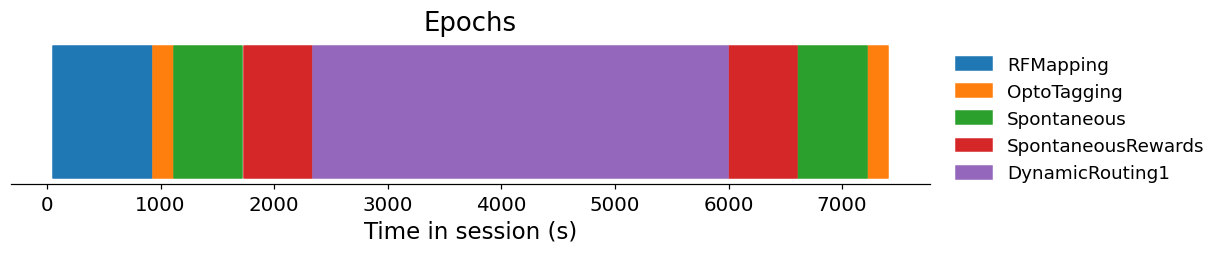

In [8]:
fig, ax = plt.subplots(figsize=(11, 2.2))
for color, (name, group) in zip(plt.cm.tab10.colors, epochs.groupby("script_name", sort=False)):
    spans = list(zip(group.start_time, (group.stop_time - group.start_time)))
    ax.broken_barh(spans, (0, 1), color=color, label=name)
ax.set(yticks=[], xlabel="Time in session (s)", title="Epochs")
ax.spines["left"].set_visible(False)
add_legend(ax, context=False)

#### Sub-Intervals 
Each epoch may be sub-divided into smaller intervals (e.g. trials) stored in other tables:

In [9]:
epochs.set_index("script_name")["interval_names"]

script_name
RFMapping             [vis_rf_mapping_trials, aud_rf_mapping_trials]
OptoTagging                                     [optotagging_trials]
Spontaneous                                                       []
SpontaneousRewards                                                []
DynamicRouting1                                [trials, performance]
SpontaneousRewards                                                []
Spontaneous                                                       []
OptoTagging                                     [optotagging_trials]
Name: interval_names, dtype: object

### `DynamicRouting1` task trials

### `trials` table

- accessible via `nwb.intervals["trials"]` or `nwb.trials`

- **each row is one trial in the task**

- column types:
    - events (`*_time` suffix) 
        - `float`, seconds relative to start of session
    - boolean metadata (`is_*` prefix)
        - for easy filtering of rows
    - other metadata (`stim_name`, `rewarded_modality`, `block_index`) 
        - `int`, `str`
- column descriptions packaged in the NWB file:

<details>
<summary><b>Trials table column descriptions</b> (click to expand)</summary>

| Column | Description |
| --- | --- |
| start_time | Start time of epoch (s) |
| stop_time | Stop time of epoch (s) |
| quiescent_start_time | Start of pre-stimulus interval in which the subject does not lick; only the last quiescent interval (which was not violated) is included |
| quiescent_stop_time | End of pre-stimulus interval in which the subject does not lick; not equal to `stim_start_time`, which factors in processing and stimulus device latency |
| stim_start_time | Onset of visual or auditory stimulus |
| stim_stop_time | Offset of visual or auditory stimulus |
| response_window_start_time | Start of interval in which the subject should lick if a GO trial, otherwise should not lick |
| response_window_stop_time | End of interval in which the subject should lick if a GO trial, otherwise should not lick |
| task_control_response_time | Time of first lick in trial according to the task control script; nan if no response registered |
| response_time | Time of first lick within the response window; nan if no lick occurred |
| reward_time | Delivery time of water reward, for contingent and non-contingent rewards |
| post_response_window_start_time | Start of null interval in which the subject awaits a new trial |
| post_response_window_stop_time | End of null interval |
| stim_name | The stimulus presented; corresponds to a unique stimulus definition, randomized over trials |
| grating_phase | Phase of the visual grating in cycles; 0 or 0.5 for visual stimuli; nan for auditory stimuli |
| block_index | 0-indexed block number, increments with each block |
| rewarded_modality | Name of the rewarded modality in each block; not an exact correspondence with values in `stim_name` |
| trial_index | 0-indexed trial number |
| trial_index_in_block | 0-indexed trial number within the block |
| repeat_index | Number of times the trial has already been presented in immediately preceding trials; nan for catch trials |
| is_response | The subject licked one or more times during the response window |
| is_correct | The subject acted correctly in the response window; includes correct reject for catch trials |
| is_incorrect | The subject acted incorrectly in the response window; includes false alarm for catch trials |
| is_hit | The subject responded in a GO trial |
| is_false_alarm | The subject responded in a NOGO trial; excludes catch trials |
| is_correct_reject | The subject did not respond in a NOGO trial; excludes catch trials |
| is_miss | The subject did not respond in a GO trial |
| is_go | Condition in which the subject should respond; target stim presented in rewarded block |
| is_nogo | Condition in which the subject should not respond; excludes catch trials |
| is_rewarded | The subject received a reward; includes non-contingent rewards |
| is_noncontingent_reward | The subject received a reward that did not depend on its response |
| is_contingent_reward | The subject received a reward for a correct response |
| is_reward_scheduled | A non-contingent reward was scheduled to occur regardless of whether it was delivered |
| is_instruction | Stimulus specifically chosen to inform the subject of a change in rewarded modality |
| is_aud_stim | An auditory stimulus was presented; excludes catch trials |
| is_vis_stim | A visual stimulus was presented; excludes catch trials |
| is_catch | No stimulus was presented |
| is_target | A stimulus was presented that the subject should respond to only in a specific block |
| is_aud_target | An auditory stimulus the subject should respond to only in a specific block |
| is_vis_target | A visual stimulus the subject should respond to only in a specific block |
| is_nontarget | A stimulus the subject should never respond to |
| is_aud_nontarget | An auditory stimulus the subject should never respond to |
| is_vis_nontarget | A visual stimulus the subject should never respond to |
| is_vis_rewarded | Visual target stimuli are rewarded |
| is_aud_rewarded | Auditory target stimuli are rewarded |
| is_block_switch | The first trial with a stimulus after a change in rewarded modality |
| is_repeat | The trial is a repetition of the previous trial due to a miss |
| is_opto | Optogenetic inactivation was applied during the trial |
| is_task_control_correct | The task control script interpreted the subject's response correctly; where False, `is_hit` or `is_miss` may be incorrect |

</details>

In [10]:
trials = nwb.trials[:]
trials.head()

,start_time,stop_time,quiescent_start_time,quiescent_stop_time,stim_start_time,stim_stop_time,response_window_start_time,response_window_stop_time,task_control_response_time,response_time,...,is_vis_target,is_nontarget,is_aud_nontarget,is_vis_nontarget,is_vis_rewarded,is_aud_rewarded,is_block_switch,is_repeat,is_opto,is_task_control_correct
id,,,,,,,,,,,,,,,,,,,,,
0,2348.22379,2353.72868,2348.22379,2349.69168,2349.752705,2350.25312,2349.80842,2350.72585,2350.22542,2350.22190,...,True,False,False,False,True,False,False,False,False,False
1,2355.06282,2360.56744,2355.06282,2356.53071,2356.591540,2357.09195,2356.64748,2357.56494,2356.98109,2356.97794,...,True,False,False,False,True,False,False,False,False,False
2,2361.43482,2366.93945,2361.43482,2362.90275,2362.963540,2363.46395,2363.01948,2363.93691,2363.30308,2363.30304,...,True,False,False,False,True,False,False,False,False,False
3,2367.13964,2372.66092,2367.13964,2368.60749,2368.668320,2369.16875,2368.72426,2369.64176,NaN,NaN,...,True,False,False,False,True,False,False,False,False,False
4,2372.82769,2378.34898,2372.82769,2374.29562,2374.356620,2374.85705,2374.41240,2375.32979,NaN,NaN,...,True,False,False,False,True,False,False,False,False,False


### Session overview

The 4 stimuli are presented in random order. The rewarded modality switches between blocks, so vis target (vis+) is only rewarded during the visual block and aud target (aud+) is only rewarded during the auditory block. 

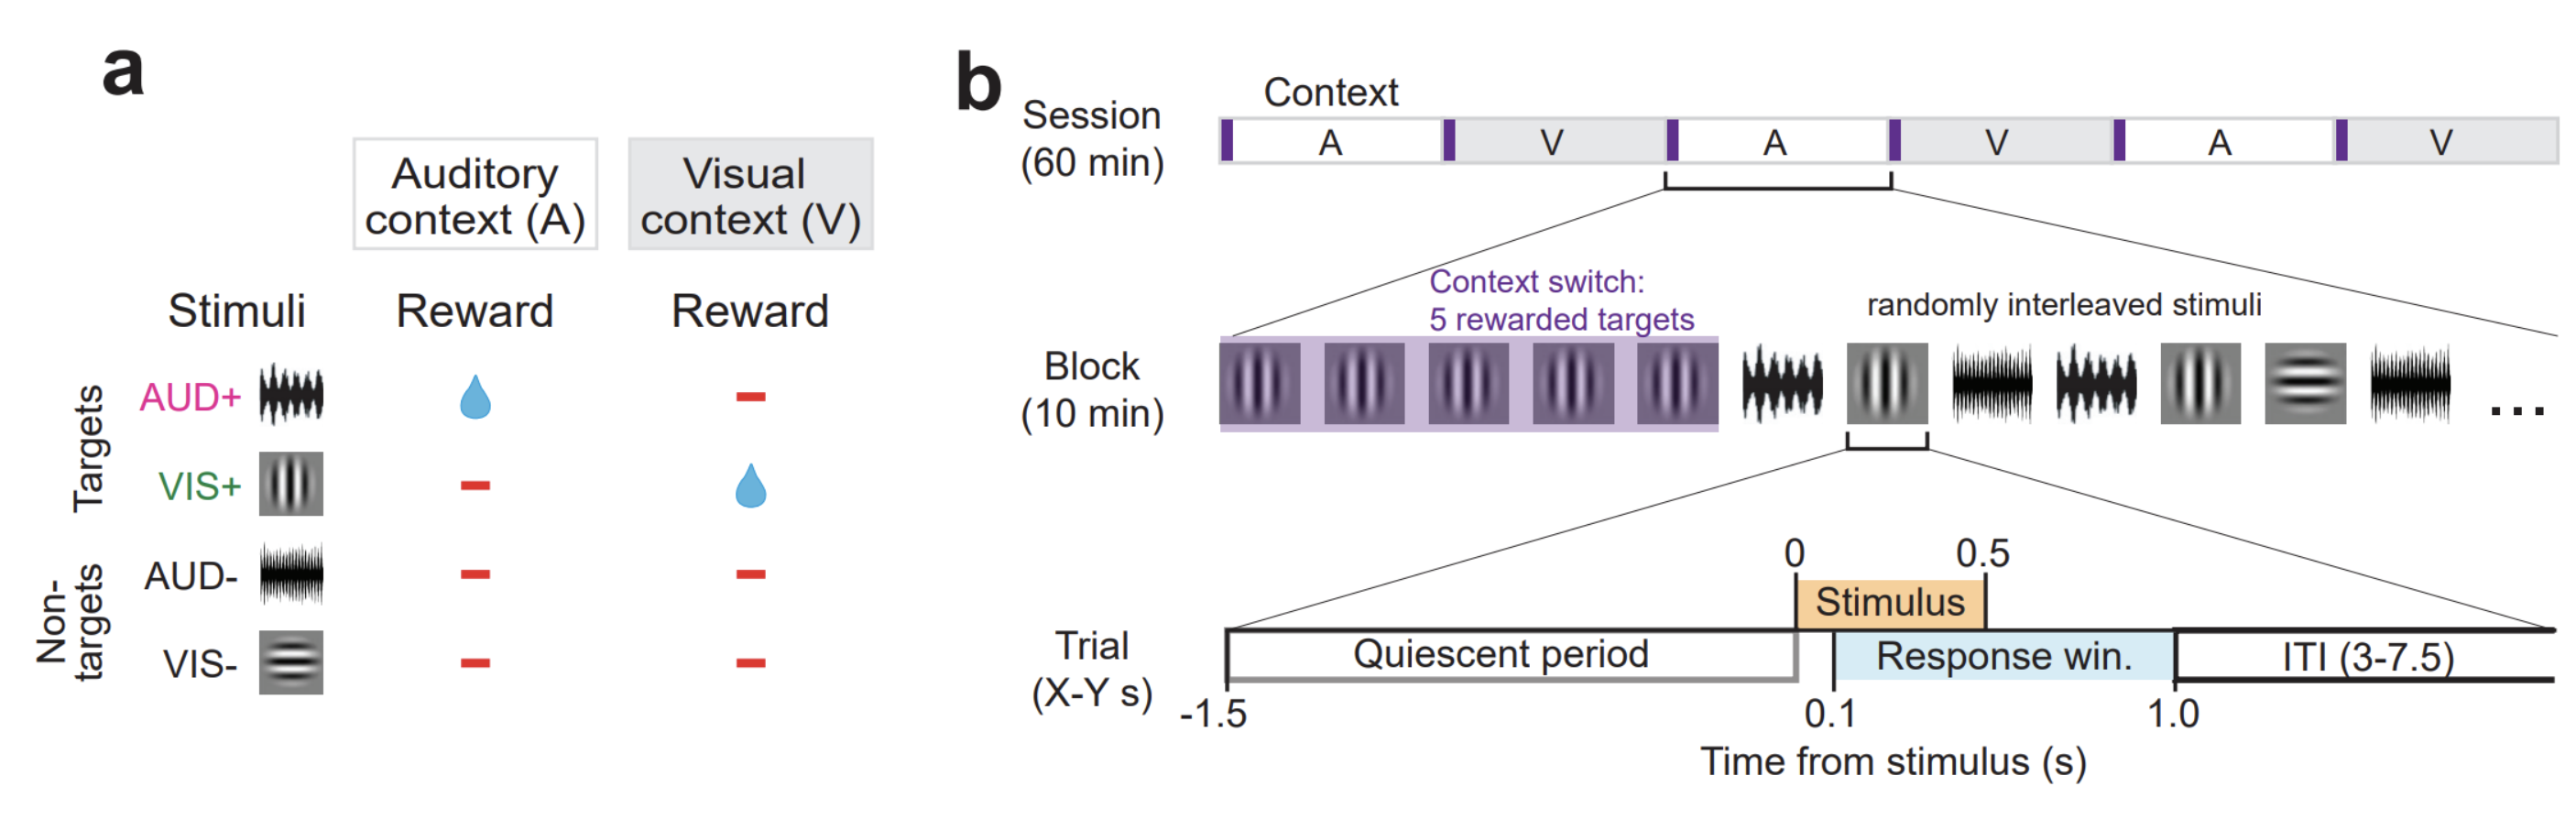

Plot description: each tick mark represents one trial. Black ticks indicate whether the mouse licked during the reponse window. Grey ticks mean the stimulus was presented and the mouse did not lick, which is the correct choice for non-rewarded stimuli. The background color indicates the rewarded modality - blue is the visual target and orange is the auditory target. 

Text(0.5, 1.0, 'Session overview')

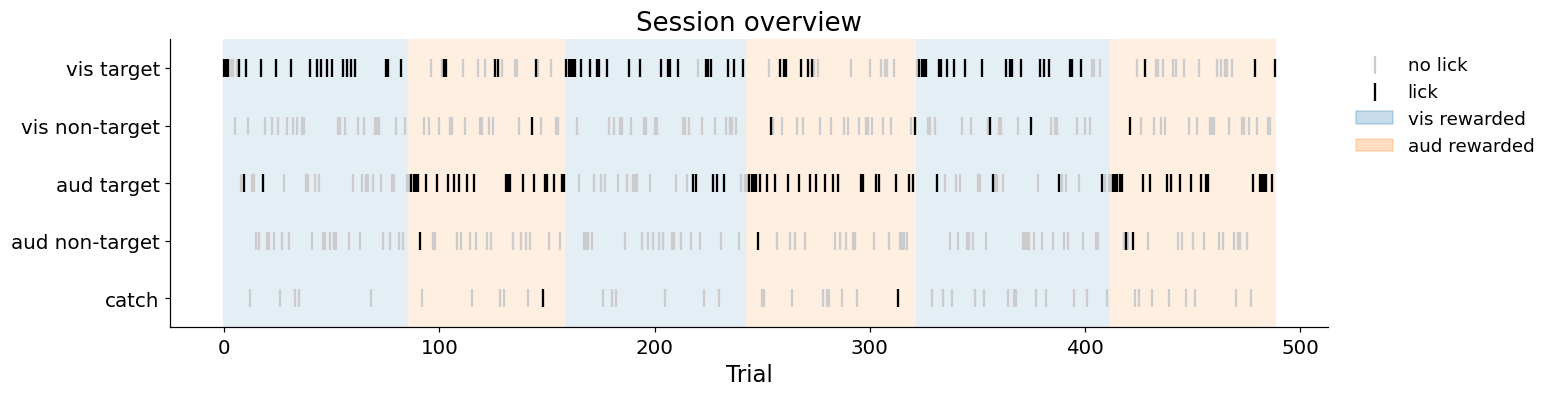

In [11]:
def plot_trials_overview(ax, trials):
    stims = [s for s in STIM_ORDER if s in set(trials.stim_name)]
    row = trials.stim_name.map({s: i for i, s in enumerate(stims)})
    shade_blocks(ax, trials)
    for licked, color, label in [(False, "0.8", "no lick"), (True, "black", "lick")]:
        is_sel = trials.is_response == licked
        ax.scatter(trials.trial_index[is_sel], row[is_sel], marker="|", s=150, lw=1.5, color=color, label=label)
    ax.set_yticks(range(len(stims)), [STIM_LABELS.get(s, s) for s in stims])
    ax.set_ylim(len(stims) - 0.5, -0.5)
    ax.set_xlabel("Trial")
    add_legend(ax)


fig, ax = plt.subplots(figsize=(14, 3.5))
plot_trials_overview(ax, trials)
ax.set_title("Session overview")

Zoom in on the first block switch:

> 💡 
> 
> The first five trials in a block (instruction trials) have a non-contingent reward scheduled - if the mice fail to lick during the response window, they still receive a reward, unexpectedly. 
>
> We'll see later how quickly they update their behavior after the block switch.

Text(0.5, 1.0, 'Block switch')

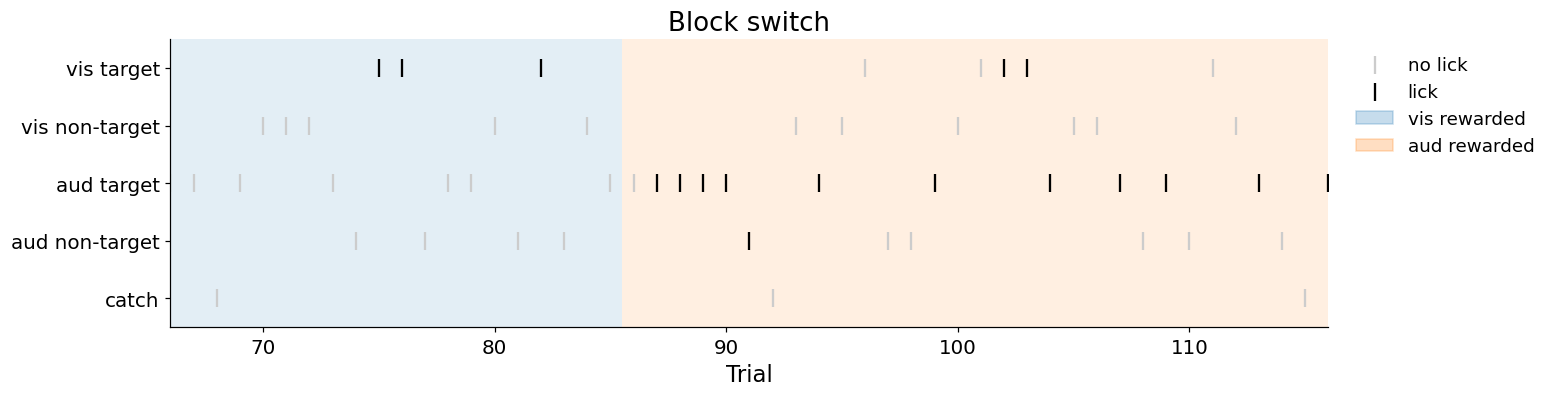

In [12]:
first_switch = trials.query("block_index == 1").trial_index.min() # finds the trial index of the first block switch (0 to 1)

fig, ax = plt.subplots(figsize=(14, 3.5))
plot_trials_overview(ax, trials)
ax.set_xlim(first_switch - 20, first_switch + 30) # set x-axis limits to show 20 trials before and 30 trials after the first block switch 
ax.set_title("Block switch")

### Timing within a trial
All times in the NWB file are in seconds relative to the start of the session.
To get response latency, subtract the stimulus onset time in each trial.

<img src="images/trial-timing.png" style="max-width: 800px; height: auto;">

> 💡 Responses to auditory stimuli are faster than to visual stimuli: phototransduction is slow
> compared to mechanotransduction.

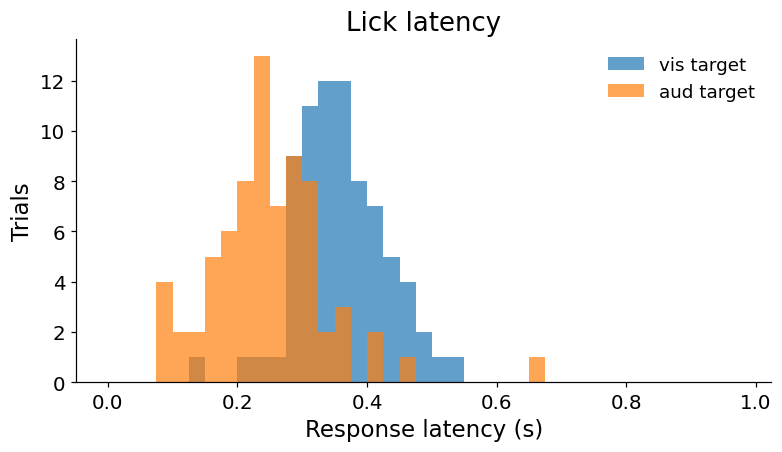

In [13]:
trials["response_latency"] = trials.response_time - trials.stim_start_time

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(0, 1.0, 0.025)
for modality, stim in [("vis", "vis1"), ("aud", "sound1")]:
    latency = trials.query("stim_name == @stim").response_latency.dropna()
    ax.hist(latency, bins=bins, color=CONTEXT_COLORS[modality], alpha=0.7, label=STIM_LABELS[stim])
ax.set(xlabel="Response latency (s)", ylabel="Trials", title="Lick latency")
ax.legend()

---
## 3. Task performance

Boolean columns in the trials table describe each trial's outcome: `is_response`, `is_hit`, `is_miss`,
`is_false_alarm`, `is_correct_reject`, ...

The NWB file also has a pre-computed `performance` table with outcomes aggregated per block. 

<details>
<summary><b>Performance table column descriptions</b> (click to expand)</summary>

| Column | Description |
| --- | --- |
| start_time | Start time of epoch (s) |
| stop_time | Stop time of epoch (s) |
| block_index | Presentation position of the block in the task (0-indexed) |
| n_trials | The number of trials in the block |
| n_responses | The number of responses the subject made in trials in the block |
| n_hits | The number of correct responses the subject made in GO trials in the block (excluding trials with scheduled reward) |
| n_contingent_rewards | The number of rewards the subject received for correct responses in the block |
| hit_rate | The proportion of correct responses the subject made in GO trials in the block (excluding trials with scheduled reward) |
| false_alarm_rate | The proportion of incorrect responses the subject made in NOGO trials in the block |
| catch_response_rate | The proportion of responses the subject made in catch trials in the block |
| rewarded_modality | The modality of the target stimulus that was rewarded in the block: normally `vis` or `aud` |
| is_first_block_aud | Whether the rewarded modality of the first block in the task was auditory |
| cross_modality_dprime | dprime across modalities; hits=response rate to rewarded target stimulus, false alarms=response rate to non-rewarded target stimulus |
| signed_cross_modality_dprime | Same as `cross_modality_dprime` but with negative values for auditory blocks |
| vis_dprime | dprime within visual modality; hits=response rate to visual target stimulus, false alarms=response rate to visual non-target stimulus |
| aud_dprime | dprime within auditory modality; hits=response rate to auditory target stimulus, false alarms=response rate to auditory non-target stimulus |
| vis_target_response_rate | The proportion of responses the subject made to visual target stimulus trials in the block (excluding trials with scheduled reward) |
| vis_nontarget_response_rate | The proportion of responses the subject made to visual nontarget stimulus trials in the block (excluding trials with scheduled reward) |
| aud_target_response_rate | The proportion of responses the subject made to auditory target stimulus trials in the block (excluding trials with scheduled reward) |
</details>

In [35]:
performance = nwb.intervals["performance"][:]
performance

,start_time,stop_time,block_index,n_trials,n_responses,n_hits,n_contingent_rewards,hit_rate,false_alarm_rate,catch_response_rate,rewarded_modality,is_first_block_aud,cross_modality_dprime,signed_cross_modality_dprime,vis_dprime,aud_dprime,vis_target_response_rate,vis_nontarget_response_rate,aud_target_response_rate,aud_nontarget_response_rate
id,,,,,,,,,,,,,,,,,,,,
0,2348.22379,2955.31550,0,86,22.0,20.0,20.0,0.869565,0.034483,4.400000,vis,False,2.376458,2.376458,3.084302,0.000000,0.944444,0.000000,0.105263,0.000000
1,2955.39894,3564.67599,1,73,29.0,21.0,21.0,0.954545,0.155556,4.833333,aud,False,2.121349,-2.121349,-0.332829,3.191708,0.333333,0.066667,1.000000,0.066667
2,3565.57660,4169.84933,2,84,27.0,22.0,22.0,0.956522,0.090909,4.500000,vis,False,2.345315,2.345315,3.649607,-0.048422,0.944444,0.000000,0.263158,0.000000
3,4171.60085,4779.42658,3,79,31.0,21.0,21.0,0.954545,0.187500,3.444444,aud,False,1.943969,-1.943969,-0.647083,3.224742,0.400000,0.117647,1.000000,0.062500
4,4781.36157,5386.95225,4,90,26.0,20.0,20.0,0.833333,0.113208,2.000000,vis,False,1.732131,1.732131,2.154253,0.000000,0.842105,0.117647,0.222222,0.000000
5,5388.00308,5987.27166,5,77,26.0,20.0,20.0,0.952381,0.125000,3.250000,aud,False,2.555538,-2.555538,-0.298005,2.779163,0.187500,0.058824,1.000000,0.133333


> 💡 The mouse responds to the target of the rewarded modality and withholds responses to the other target,
> flipping back and forth across blocks.

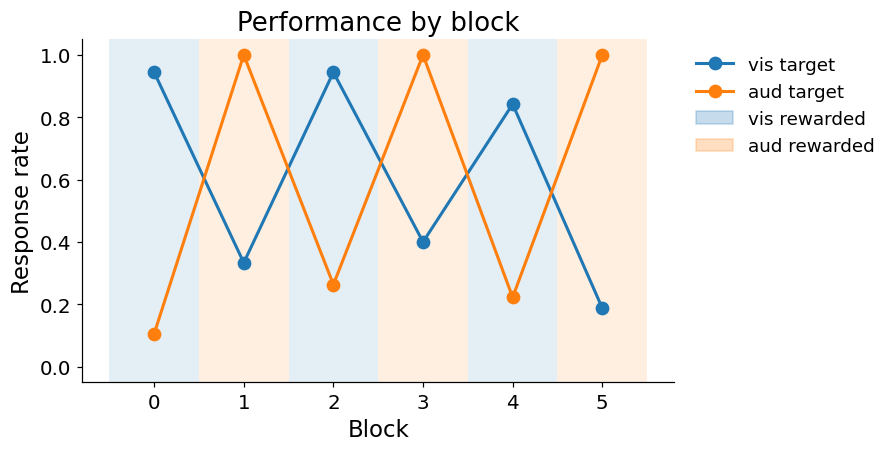

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
shade_blocks(ax, trials, "block_index", "block_index")
for modality in ["vis", "aud"]:
    ax.plot(performance.block_index, performance[f"{modality}_target_response_rate"],
            "o-", ms=8, color=CONTEXT_COLORS[modality], label=f"{modality} target")
ax.set(xlabel="Block", ylabel="Response rate", ylim=(-0.05, 1.05),
       xticks=performance.block_index, title="Performance by block")
add_legend(ax)

#### Misses after a block switch
Misses (no lick to the rewarded target) in the first 15 trials of each block:

> 💡 
> 
> Once the mice learn the task, they typically only need one "miss" on the first trial of a block to update their behavior, and make very few misses in the rest of the block.

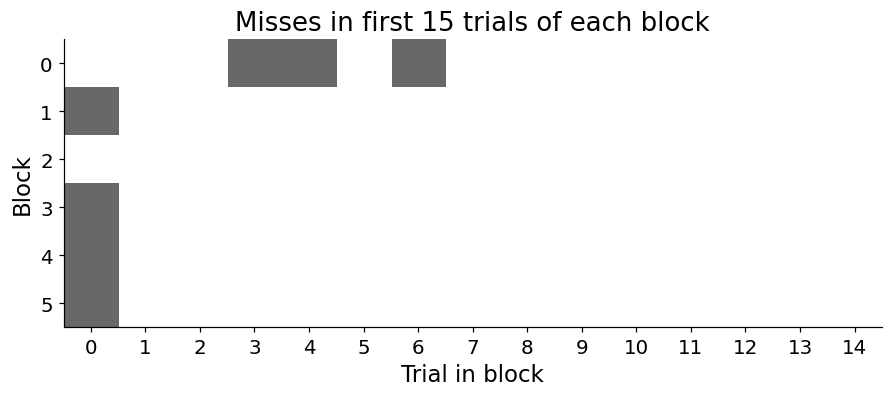

In [37]:
miss_grid = (
    trials.query("trial_index_in_block < 15")
    .pivot_table(index="block_index", columns="trial_index_in_block", values="is_miss", aggfunc="max")
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.imshow(miss_grid.to_numpy(dtype=float), cmap="Greys", vmin=0, vmax=1.5, aspect="auto")
ax.set(xticks=range(miss_grid.shape[1]), yticks=range(miss_grid.shape[0]),
       xlabel="Trial in block", ylabel="Block", title="Misses in first 15 trials of each block")
plt.show()

---
## 4. Neural data

### `units` table
- **each row is one recorded (putative) neuron from spike-sorting**

- metadata about each unit

- list-like `spike_times` and `spike_amplitudes` columns

- array-like `waveform_mean` and `waveform_sd` columns, which are be very large compared to the scalar metadata (excluded from these NWB files)

<details>
<summary><b>Units table column descriptions</b> (click to expand)</summary>

| Column | Description |
| --- | --- |
| activity_drift | Measure of drift in unit activity over the session |
| amplitude | Amplitude (µV) of the average spike waveform |
| amplitude_cutoff | Estimated fraction of spikes missing from this unit (default threshold = 0.1) |
| amplitude_cv_median | Median coefficient of variation of spike amplitudes |
| amplitude_cv_range | Range of coefficient of variation of spike amplitudes |
| amplitude_median | Median spike amplitude (µV) |
| ccf_ap | Anterior-posterior coordinate in Allen CCF atlas (µm) |
| ccf_dv | Dorsal-ventral coordinate in Allen CCF atlas (µm) |
| ccf_ml | Medial-lateral coordinate in Allen CCF atlas (µm) |
| cluster_id | Identifier for this unit assigned by the spike sorting algorithm (unique within each probe) |
| d_prime | Measure of how separable this unit's waveforms are from its neighbors' |
| decoder_label | Predicted cell type label from decoder |
| decoder_probability | Confidence of decoder cell type prediction [0-1] |
| default_qc | Whether the unit passes default quality control criteria |
| device_name | Name of the recording device |
| drift_mad | Median absolute deviation of unit drift |
| drift_ptp | Peak-to-peak amplitude of unit drift (µm) |
| drift_std | Standard deviation of unit drift |
| electrode_group_name | Name of the electrode group the unit was recorded from |
| exp_decay | Exponential decay of the autocorrelogram |
| firing_range | Range of firing rates across the session |
| firing_rate | Mean spike rate across the whole session (Hz) |
| half_width | Half-width of the mean spike waveform (s) |
| is_not_drift | Boolean indicating unit is not classified as a drift artifact |
| is_qc_pass | Boolean indicating unit passes quality control |
| isi_violations_count | Number of inter-spike interval violations (<1.5 ms) |
| isi_violations_ratio | Measure of unit contamination from refractory period violations (default threshold = 0.5) |
| isolation_distance | Distance to nearest cluster in Mahalanobis space; higher is better |
| l_ratio | Measure of how separable this unit's waveforms are from its neighbors'; lower is better |
| location | brain structure (acronym) |
| nn_hit_rate | Fraction of spikes with nearest neighbor from same cluster |
| nn_miss_rate | Measure of fraction of spikes missing from this unit |
| num_negative_peaks | Number of negative peaks in the mean spike waveform |
| num_positive_peaks | Number of positive peaks in the mean spike waveform |
| num_spikes | Total number of spikes detected for the unit |
| peak_channel | Channel index with the largest amplitude waveform |
| peak_electrode | Electrode index with the largest amplitude spike waveform |
| peak_to_valley | Time (s) between waveform peak and trough |
| peak_trough_ratio | Peak-to-trough ratio of the average spike waveform |
| presence_ratio | Fraction of the session over which this unit had spikes detected (default threshold = 0.9) |
| recovery_slope | Slope of the waveform between the trough and the peak (V/s) |
| repolarization_slope | Slope of the waveform back to 0 after the peak (V/s) |
| rp_contamination | Estimated contamination from refractory period violations |
| rp_violations | Number of refractory period violations |
| silhouette | Measure of unit contamination based on cluster separation |
| sliding_rp_violation | Sliding refractory period violation metric |
| snr | Ratio of waveform amplitude relative to background noise on the peak channel |
| spike_amplitudes | Array of individual spike amplitudes (µV) |
| spread | Distance the waveform extends above and below the peak channel (µm) |
| structure | Brain structure acronym where the unit was recorded |
| sync_spike_2 | Synchrony of unit spikes within 2 ms windows |
| sync_spike_4 | Synchrony of unit spikes within 4 ms windows |
| sync_spike_8 | Synchrony of unit spikes within 8 ms windows |
| unit_id | Unique UUID identifier for the unit |
| velocity_above | Speed of waveform propagation above the peak channel (V/s) |
| velocity_below | Speed of waveform propagation below the peak channel (V/s) |
| spike_times | Timestamps (s) of each detected spike for the unit |
| obs_intervals | Time intervals during which the unit was observed/recorded |
| electrode_group | The electrode group that each spike unit came from |


Let's load the units dataframe without the unnecessary columns:

</details>

In [17]:
# Load units table, excluding large arrays to save memory and speed 
units = nwb.units.to_dataframe(exclude={"spike_amplitudes", "waveform_mean", "waveform_sd", "electrode_group"})
units[["unit_id", "structure", "location", "firing_rate", "num_spikes", "is_qc_pass"]].head()

,unit_id,structure,location,firing_rate,num_spikes,is_qc_pass
id,,,,,,
0,742903_2024-10-23_A-0,CP,CP,3.634028,26845.0,True
1,742903_2024-10-23_A-1,CP,CP,0.083524,617.0,False
2,742903_2024-10-23_A-3,CP,CP,36.334593,268408.0,True
3,742903_2024-10-23_A-4,CP,CP,0.914565,6756.0,False
4,742903_2024-10-23_A-5,CP,CP,0.253008,1869.0,False


`is_qc_pass` allows quick filtering for units whose activity is stable over the task and that don't look like noise:
- `activity_drift < 0.1`
- `amplitude_cutoff <= 0.1`
- `presence_ratio > 0.7`
- `decoder_label != "noise"`

### Where were units recorded?
- `structure` is the coarse brain area label
- `location` is the more specific label, matching `acronym` in the Allen CCF ontology

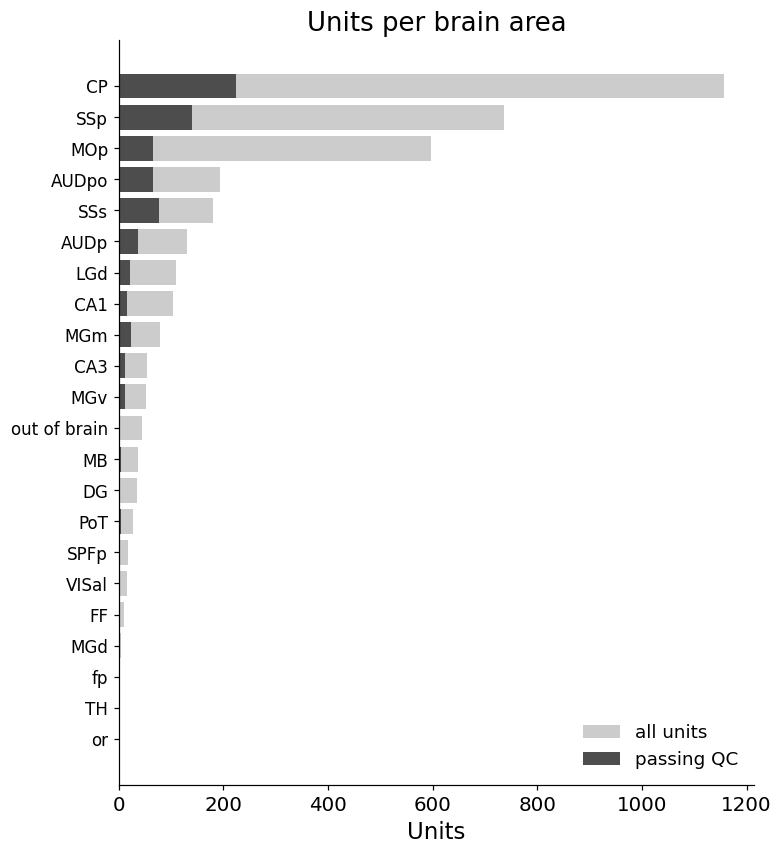

In [18]:
area_counts = pd.DataFrame({
    "all units": units.structure.value_counts(),
    "passing QC": units.query("is_qc_pass").structure.value_counts(),
}).fillna(0).astype(int).sort_values("all units")

fig, ax = plt.subplots(figsize=(7, 0.28 * len(area_counts) + 1.5))
ax.barh(area_counts.index, area_counts["all units"], color="0.8", label="all units")
ax.barh(area_counts.index, area_counts["passing QC"], color="0.3", label="passing QC")
ax.set(xlabel="Units", title="Units per brain area")
ax.tick_params(axis="y", labelsize=11)
ax.legend(loc="lower right")

Probe insertion tracks are manually annotated and warped to a reference brain, so every recording site has
coordinates in a common space across subjects (the Allen CCF, in µm). More info: https://allenswdb.github.io/background/CCF.html

Each site below is colored with the standard Allen atlas color for its brain area.

> 💡 The physical probes are straight, but appear wobbly due to the warping into the CCF.

In [19]:
CCF_URL = "https://raw.githubusercontent.com/cortex-lab/allenCCF/refs/heads/master/structure_tree_safe_2017.csv"
ccf_tree = pd.read_csv(CCF_URL, usecols=["acronym", "name", "color_hex_triplet"]).drop_duplicates("acronym")
AREA_COLORS = dict(zip(ccf_tree.acronym, "#" + ccf_tree.color_hex_triplet.astype(str).str.zfill(6)))

sites = units.dropna(subset=["ccf_ap", "ccf_dv", "ccf_ml"]).query("decoder_label != 'noise'")

def plot_sites(ax_sagittal, ax_coronal, sites):
    for structure, group in sites.groupby("structure"):
        color = AREA_COLORS.get(structure, "#999999")
        ax_sagittal.scatter(group.ccf_ap / 1000, group.ccf_dv / 1000, s=12, color=color, ec="none", label=structure)
        ax_coronal.scatter(group.ccf_ml / 1000, group.ccf_dv / 1000, s=12, color=color, ec="none")
    ax_sagittal.set(xlabel="Anterior → posterior (mm)", ylabel="Dorsal → ventral (mm)", title="Side view")
    ax_coronal.set(xlabel="Medial-lateral (mm)", title="Front view")
    for ax in (ax_sagittal, ax_coronal):
        ax.set_aspect("equal")
        if not ax.yaxis_inverted():
            ax.invert_yaxis()   # dorsal at the top

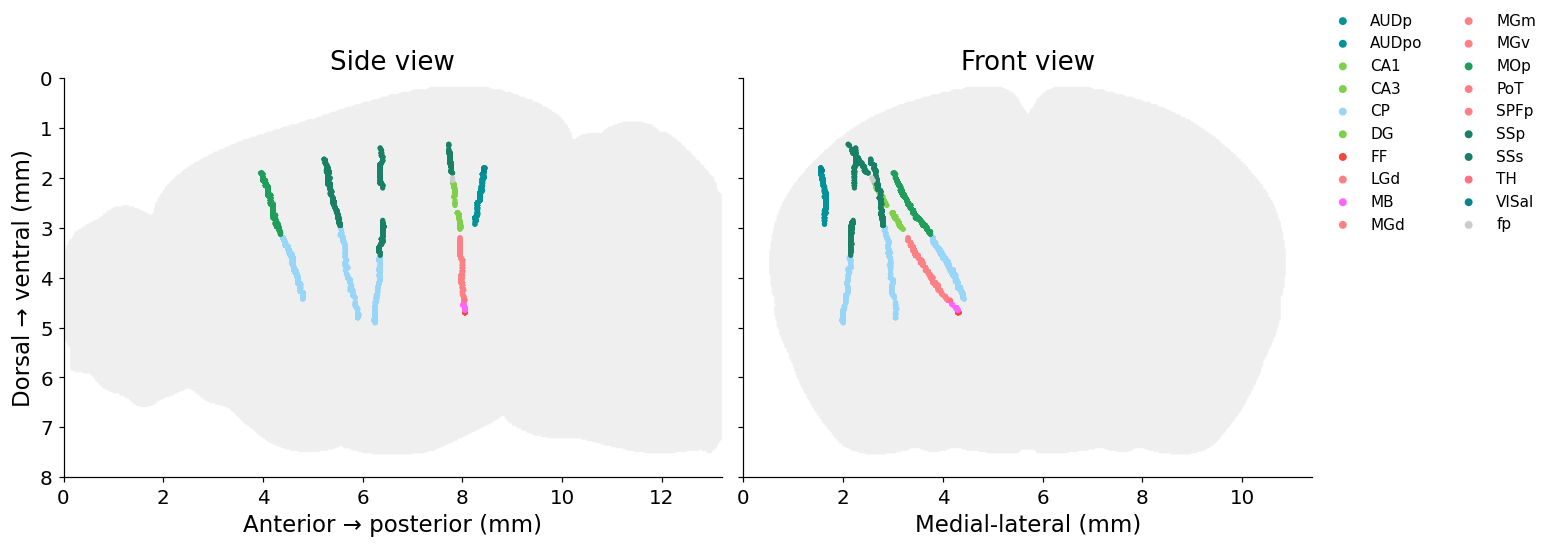

In [20]:
bg.config.write_config_value("brainglobe_dir", "/data/.brainglobe")
atlas = bg.BrainGlobeAtlas("allen_mouse_25um")

res_mm = atlas.resolution[0] / 1000
n_ap, n_dv, n_ml = atlas.annotation.shape           # volume axes: AP, DV, ML
in_brain = atlas.annotation > 0

fig, (ax_sag, ax_cor) = plt.subplots(1, 2, figsize=(14, 5), sharey=True,
                                     gridspec_kw={"width_ratios": [n_ap, n_ml]})
ax_sag.imshow(in_brain.any(axis=2).T, cmap="Greys", vmax=8, extent=[0, n_ap * res_mm, n_dv * res_mm, 0])
ax_cor.imshow(in_brain.any(axis=0), cmap="Greys", vmax=8, extent=[0, n_ml * res_mm, n_dv * res_mm, 0])
plot_sites(ax_sag, ax_cor, sites)
fig.legend(loc="outside right upper", ncols=2, fontsize=10, markerscale=1.5)

### A single unit

Choose a unit by its `unit_id`, or pick one with a query on the units table.

In [38]:
UNIT_ID = "742903_2024-10-23_F-178" 

# or pick a random unit that passes QC in an area of interest:
# UNIT_ID = units.query("is_qc_pass and structure == 'MOp' and firing_rate > 5").sample(1).unit_id.iloc[0]

unit = units.set_index("unit_id").loc[UNIT_ID]
spike_times = np.asarray(unit.spike_times)   # seconds, sorted
unit[["structure", "location", "electrode_group_name", "firing_rate", "is_qc_pass"]]

structure                   MOp
location                  MOp6a
electrode_group_name     probeF
firing_rate             8.73007
is_qc_pass                 True
Name: 742903_2024-10-23_F-178, dtype: object

### Spikes around one trial
`spike_times` covers the whole session. To relate spikes to the task, take the spikes in a window around a
trial's stimulus onset and subtract the onset time.

<img src="images/spikes.png" width="800">

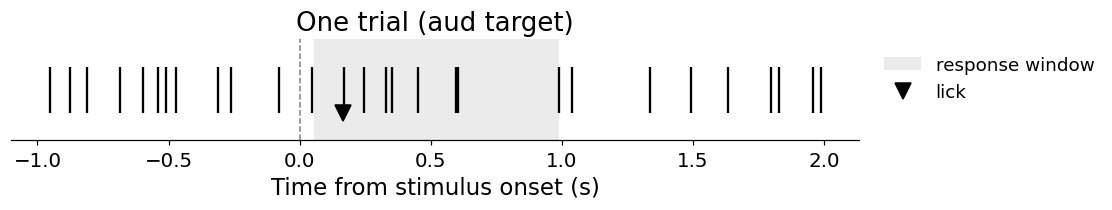

In [22]:
trial = trials.query("stim_name == 'sound1' and is_hit").iloc[0]
onset = trial.stim_start_time
spikes_in_trial = spike_times[(spike_times > onset - 1) & (spike_times < onset + 2)] - onset

response_window = (
    (trials.response_window_start_time - trials.stim_start_time).median(),
    (trials.response_window_stop_time - trials.stim_start_time).median(),
)

fig, ax = plt.subplots(figsize=(10, 1.8))
ax.axvspan(*response_window, color="0.92", lw=0, label="response window")
ax.eventplot(spikes_in_trial, colors="black", linelengths=0.8, linewidths=1.5)
ax.axvline(0, color="0.5", ls="--", lw=1)
ax.plot(trial.response_time - onset, 0.6, "v", color="black", ms=10, label="lick")
ax.set(yticks=[], xlabel="Time from stimulus onset (s)", title=f"One trial ({STIM_LABELS['sound1']})")
ax.spines["left"].set_visible(False)
add_legend(ax, context=False)

### Raster and PSTH
Stack many trials of the same stimulus (raster), then average the spike counts in small time bins
to get the firing rate (peri-stimulus time histogram, PSTH). Here trials are split by block type.

> 💡 This unit responds to the auditory target regardless if it's rewarded or not. 

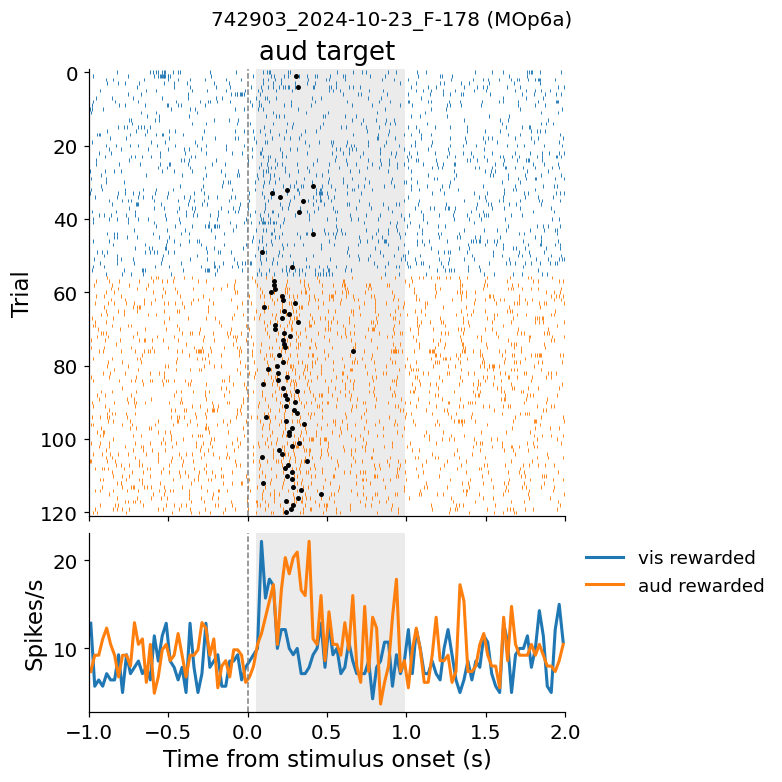

In [23]:
def align_spikes(spike_times, event_times, window):
    """List of spike-time arrays, one per event, relative to the event time."""
    starts = np.searchsorted(spike_times, event_times + window[0])
    stops = np.searchsorted(spike_times, event_times + window[1])
    return [spike_times[a:b] - t for a, b, t in zip(starts, stops, event_times)]


def plot_raster_psth(ax_raster, ax_psth, spike_times, trials, stim_name, window=(-1, 2), bin_size=0.025):
    bins = np.arange(window[0], window[1] + bin_size, bin_size)
    first_row = 0
    for modality, color in CONTEXT_COLORS.items():
        context_trials = trials.query("stim_name == @stim_name and rewarded_modality == @modality")
        if context_trials.empty:
            continue
        aligned = align_spikes(spike_times, context_trials.stim_start_time.to_numpy(), window)
        rows = first_row + np.arange(len(aligned))
        ax_raster.eventplot(aligned, lineoffsets=rows, linelengths=1, linewidths=0.6, colors=color)
        ax_raster.scatter(context_trials.response_time - context_trials.stim_start_time, rows,
                          s=5, color="black", zorder=3)   # first lick (if any)
        rate = sum(np.histogram(s, bins)[0] for s in aligned) / len(aligned) / bin_size
        ax_psth.plot(bins[:-1] + bin_size / 2, rate, color=color, label=f"{modality} rewarded")
        first_row += len(aligned)

    for ax in (ax_raster, ax_psth):
        ax.axvspan(*response_window, color="0.92", lw=0, zorder=-1)
        ax.axvline(0, color="0.5", ls="--", lw=1)
    ax_raster.set(xlim=window, ylim=(first_row, -1), ylabel="Trial", title=STIM_LABELS.get(stim_name, stim_name))
    ax_psth.set(xlabel="Time from stimulus onset (s)", ylabel="Spikes/s")


fig, (ax_raster, ax_psth) = plt.subplots(2, 1, figsize=(7, 7), sharex=True, height_ratios=[3, 1.2])
plot_raster_psth(ax_raster, ax_psth, spike_times, trials, "sound1")
fig.suptitle(f"{UNIT_ID} ({unit.location})", fontsize=13)
add_legend(ax_psth, context=False)

#### All four stimuli 

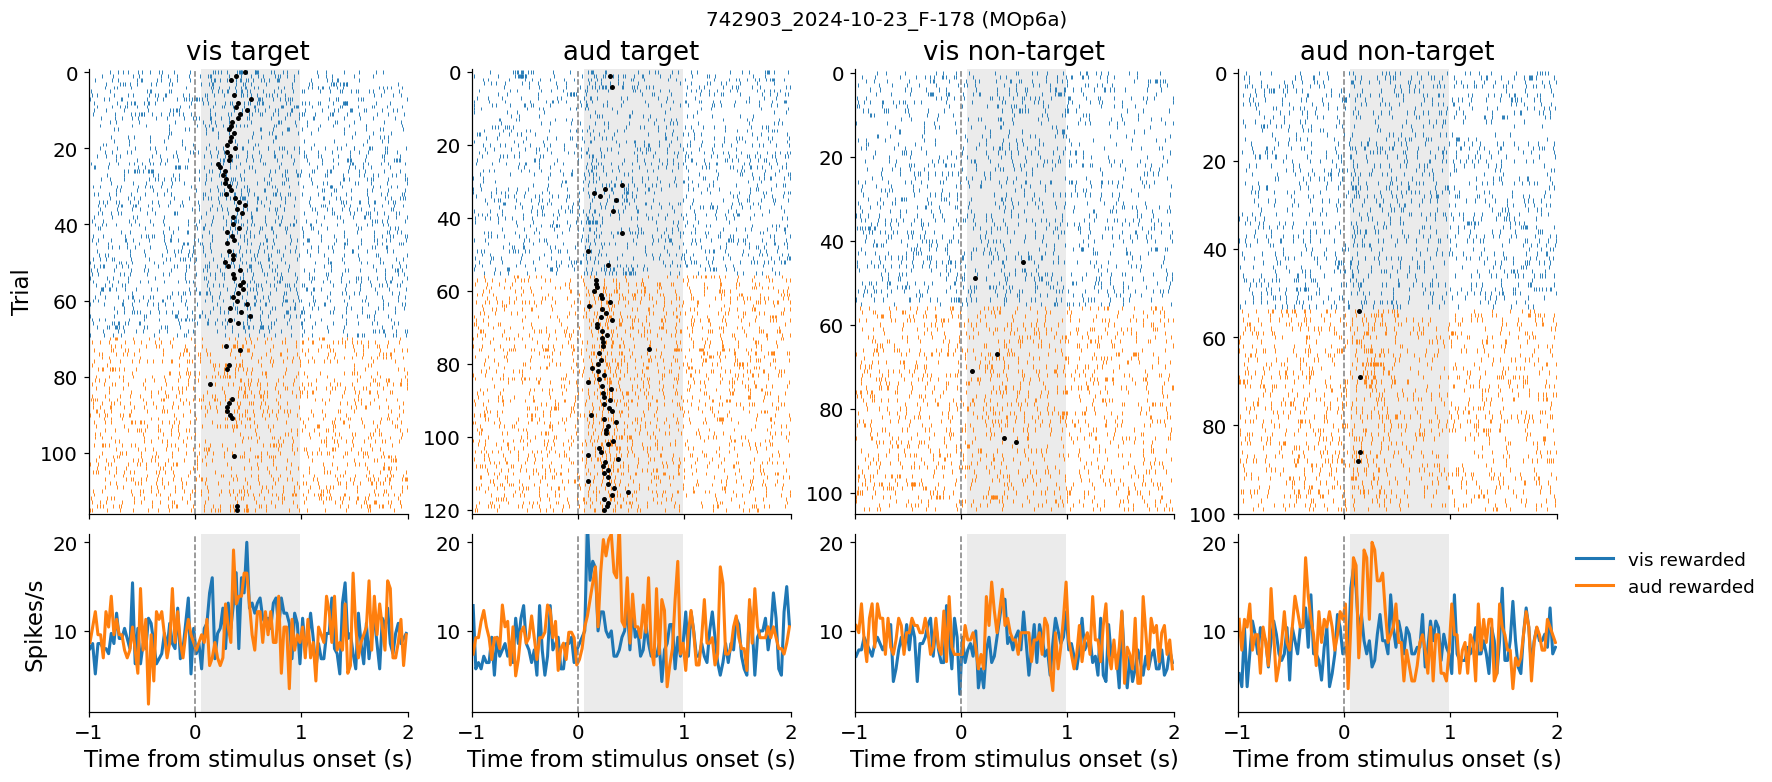

In [24]:
stims = ["vis1", "sound1", "vis2", "sound2"]
fig, axes = plt.subplots(2, len(stims), figsize=(16, 7), sharex=True, height_ratios=[3, 1.2])
for (ax_raster, ax_psth), stim in zip(axes.T, stims):
    plot_raster_psth(ax_raster, ax_psth, spike_times, trials, stim)
    ax_psth.sharey(axes[1, 0])   # same firing-rate scale in every PSTH
for ax in axes[:, 1:].flat:
    ax.set_ylabel("")
fig.suptitle(f"{UNIT_ID} ({unit.location})", fontsize=13)
add_legend(axes[1, -1], context=False)

---
## 5. Continuous behavior

### Running speed
Timeseries are stored in `nwb.processing["behavior"]`, with a `data` array and matching `timestamps`.

In [25]:
running_speed = nwb.processing["behavior"]["running_speed"]
rs_times = running_speed.timestamps[:]
rs_speed = running_speed.data[:]

print(f"{len(rs_times)} samples at {1 / np.median(np.diff(rs_times)):.0f} Hz, in {running_speed.unit}")

431581 samples at 60 Hz, in cm/s


Running speed for 3 minutes on either side of the first block switch:

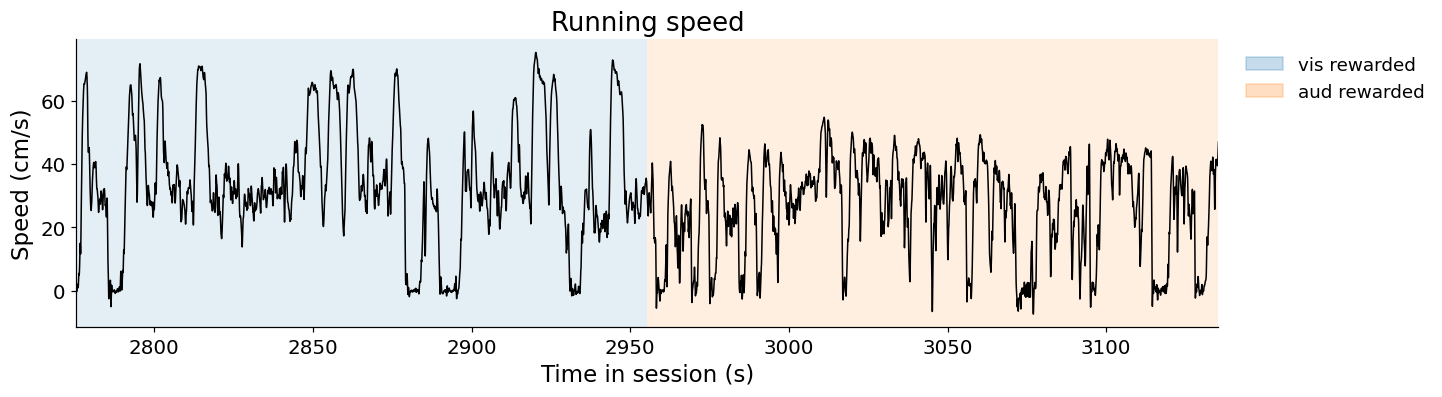

In [26]:
switch_time = trials.query("block_index == 1").start_time.min()
in_window = np.abs(rs_times - switch_time) < 180

fig, ax = plt.subplots(figsize=(13, 3.5))
shade_blocks(ax, trials, "start_time", "stop_time", pad=0)
ax.plot(rs_times[in_window], rs_speed[in_window], color="black", lw=1)
ax.set(xlim=(switch_time - 180, switch_time + 180), xlabel="Time in session (s)",
       ylabel=f"Speed ({running_speed.unit})", title="Running speed")
add_legend(ax)

### Running speed around stimulus onset
To compare across trials, sample the signal on a common time grid around each stimulus onset, then average.
The same two helpers work for any continuous signal.

> 💡 Running speed appears to be higher during auditory-rewarded blocks. Is this consistent across subjects?

Text(0, 0.5, 'Speed (cm/s)')

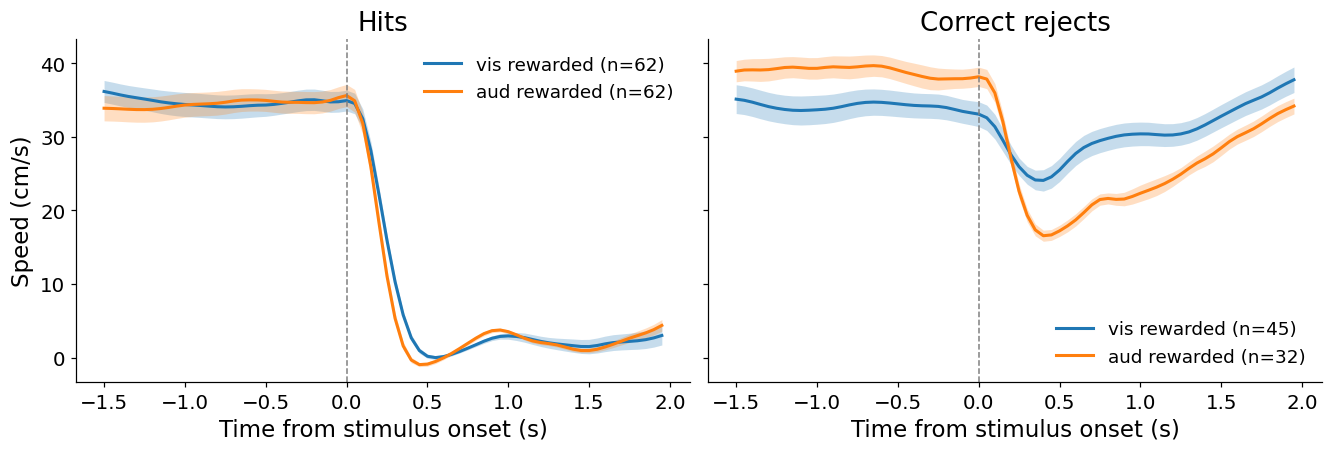

In [27]:
def align_to_events(times, values, event_times, window=(-1.5, 2.0), step=0.05):
    """Sample a continuous signal around each event. Returns (time grid, trials x time array)."""
    grid = np.arange(window[0], window[1], step)
    in_range = (event_times + window[0] >= times[0]) & (event_times + window[1] <= times[-1])
    return grid, np.array([np.interp(t + grid, times, values) for t in event_times[in_range]])


def plot_mean_by_context(ax, times, values, trials):
    """Mean ± SEM of a signal around stimulus onset, one line per block type."""
    for modality, color in CONTEXT_COLORS.items():
        onsets = trials.query("rewarded_modality == @modality").stim_start_time.to_numpy()
        grid, traces = align_to_events(times, values, onsets)
        mean, sem = traces.mean(axis=0), traces.std(axis=0, ddof=1) / np.sqrt(len(traces))
        ax.plot(grid, mean, color=color, label=f"{modality} rewarded (n={len(traces)})")
        ax.fill_between(grid, mean - sem, mean + sem, color=color, alpha=0.25, lw=0)
    ax.axvline(0, color="0.5", ls="--", lw=1)
    ax.set_xlabel("Time from stimulus onset (s)")
    ax.legend()


# target trials with a correct outcome
target_trials = trials.query("(is_vis_target or is_aud_target) and (is_hit or is_correct_reject)")
outcomes = {"Hits": "is_hit", "Correct rejects": "is_correct_reject"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, column) in zip(axes, outcomes.items()):
    plot_mean_by_context(ax, rs_times, rs_speed, target_trials.query(column))
    ax.set_title(title)
axes[0].set_ylabel(f"Speed ({running_speed.unit})")

### Face tracking with Lightning Pose
Markerless pose estimation with deep learning tracks keypoints on the face in the side camera video.

<img src="images/nose_cam.png" style="max-width: 600px; height: auto;">

In [28]:
lp_side = nwb.processing["behavior"]["lp_side_camera"]
lp_side.colnames

('ear_base_l_likelihood',
 'ear_base_l_pca_error',
 'ear_base_l_temporal_norm',
 'ear_base_l_x',
 'ear_base_l_y',
 'ear_tip_l_likelihood',
 'ear_tip_l_pca_error',
 'ear_tip_l_temporal_norm',
 'ear_tip_l_x',
 'ear_tip_l_y',
 'eye_bottom_l_likelihood',
 'eye_bottom_l_pca_error',
 'eye_bottom_l_temporal_norm',
 'eye_bottom_l_x',
 'eye_bottom_l_y',
 'eye_top_l_likelihood',
 'eye_top_l_pca_error',
 'eye_top_l_temporal_norm',
 'eye_top_l_x',
 'eye_top_l_y',
 'jaw_likelihood',
 'jaw_pca_error',
 'jaw_temporal_norm',
 'jaw_x',
 'jaw_y',
 'nose_tip_likelihood',
 'nose_tip_pca_error',
 'nose_tip_temporal_norm',
 'nose_tip_x',
 'nose_tip_y',
 'nostril_l_likelihood',
 'nostril_l_pca_error',
 'nostril_l_temporal_norm',
 'nostril_l_x',
 'nostril_l_y',
 'tongue_base_l_likelihood',
 'tongue_base_l_pca_error',
 'tongue_base_l_temporal_norm',
 'tongue_base_l_x',
 'tongue_base_l_y',
 'tongue_tip_likelihood',
 'tongue_tip_pca_error',
 'tongue_tip_temporal_norm',
 'tongue_tip_x',
 'tongue_tip_y',
 'whisker

Each keypoint has a likelihood score. Check its distribution and drop low-confidence detections.
Load only the columns you need: the full table is large.

[Text(0.5, 0, 'Likelihood'),
 Text(0, 0.5, 'Frames'),
 Text(0.5, 1.0, 'ear_base_l')]

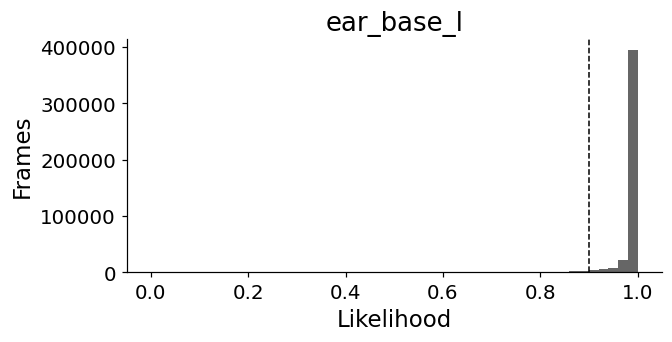

In [29]:
KEYPOINT = "ear_base_l_y"
likelihood_col = KEYPOINT[:-2] + "_likelihood"

keep = {"timestamps", KEYPOINT, likelihood_col}
lp = lp_side.to_dataframe(exclude=set(lp_side.colnames) - keep)

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(lp[likelihood_col], bins=50, color="0.4")
ax.axvline(0.9, color="black", ls="--", lw=1)
ax.set(xlabel="Likelihood", ylabel="Frames", title=KEYPOINT[:-2])

> 💡 The ear sits slightly higher during auditory-rewarded blocks, even before stimulus onset!

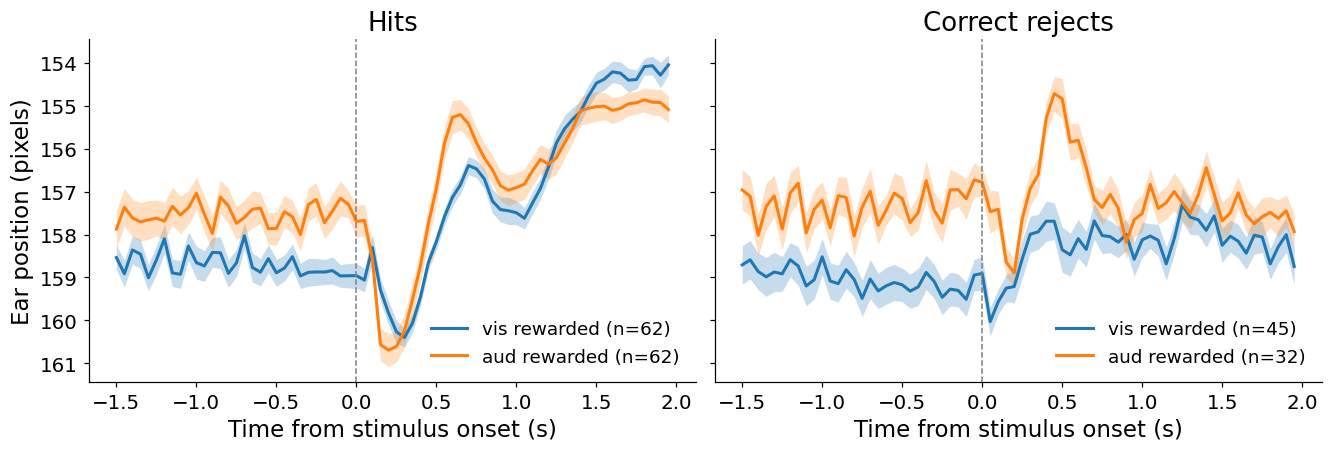

In [30]:
lp_good = lp.query(f"{likelihood_col} > 0.9")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (title, column) in zip(axes, outcomes.items()):
    plot_mean_by_context(ax, lp_good.timestamps.to_numpy(), lp_good[KEYPOINT].to_numpy(), target_trials.query(column))
    ax.set_title(title)
axes[0].set_ylabel("Ear position (pixels)")
axes[0].invert_yaxis()   # image coordinates: y increases downward, so up is up